# VQA v2 Top-1000 答案分类实验

使用官方 train 的答案频次建立 Top-1000 词表，按图片密度分层抽样得到训练题。
开发集有 800 张与训练集不相交的图片：词表内题用于主要分类评价；
同一批图片的全部题用于检查答案覆盖率和词表外表现。
本实验不读取标注的 `answer_type` 来决定模型输出；它只用于结果分组。
结果均为开发集结果，不能称作 VQA v2 官方测试成绩。

数据：https://visualqa.org/download ；模型：https://github.com/openai/CLIP 。


In [ ]:
from __future__ import annotations

import copy
import hashlib
import json
import math
import os
import platform
import random
import re
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset

ROOT = Path.cwd()
if not (ROOT / "scripts" / "prepare_data.py").is_file():
    ROOT = next((p for p in (ROOT, *ROOT.parents)
                 if (p / "scripts" / "prepare_data.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run the notebook from the repository root")
os.chdir(ROOT)
DATA = Path(os.environ.get("VQA_DATA_ROOT", ROOT / "data")).expanduser().resolve()
VENDOR = Path(os.environ.get("VQA_VENDOR_ROOT", ROOT / "vendor")).expanduser().resolve()
sys.path[:0] = [str(VENDOR / "python"), str(VENDOR / "CLIP-main"), str(ROOT / "scripts")]
import clip
from prepare_data import joined_rows

SEED = 42
EPOCHS = 16
BATCH_SIZE = 256
FEATURE_SCALE = math.sqrt(512)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")


## 1. 数据划分与词表覆盖率

词表仅由官方训练标注构建。开发图片随机分成 600 张选模图片和 200 张置信度
校准图片；两组按图片 ID 隔离。所有模型共享相同样本、词表、分类头和训练轮次。
Top-1000 开发集按答案过滤，因此其准确率是高频答案条件下的成绩。


In [ ]:
train_manifest_path = DATA / "manifest_top1000.json"
dev_manifest_path = DATA / "manifest_top1000_dev.json"
train_manifest = json.loads(train_manifest_path.read_text(encoding="utf-8"))
dev_manifest = json.loads(dev_manifest_path.read_text(encoding="utf-8"))
vocabulary = train_manifest["vocabulary"]
assert len(vocabulary) == 1000 and vocabulary == dev_manifest["vocabulary"]
answer_to_id = {answer: i for i, answer in enumerate(vocabulary)}
train_rows = train_manifest["rows"]
dev_rows = dev_manifest["rows"]
train_ids = {row["image_id"] for row in train_rows}
dev_ids = sorted({row["image_id"] for row in dev_rows})
assert len(train_rows) == train_manifest["stats"]["train"]["questions"]
assert len(dev_rows) == dev_manifest["stats"]["dev"]["questions"]
assert len(train_ids) == 2000 and len(dev_ids) == 800
assert not (train_ids & set(dev_ids))

val_rows = joined_rows("val")
all_dev = [row for row in val_rows if row["image_id"] in set(dev_ids)]
for row in all_dev:
    row["label_id"] = answer_to_id.get(row["answer"], -1)
assert {row["question_id"] for row in dev_rows} <= {row["question_id"] for row in all_dev}
random.Random(SEED + 101).shuffle(dev_ids)
selection_ids, calibration_ids = set(dev_ids[:600]), set(dev_ids[600:])
selection_rows = [r for r in dev_rows if r["image_id"] in selection_ids]
calibration_rows = [r for r in dev_rows if r["image_id"] in calibration_ids]
assert len(selection_ids) == 600 and len(calibration_ids) == 200
assert not (selection_ids & calibration_ids)
coverage = len(dev_rows) / len(all_dev)
seen_train_labels = {row["label_id"] for row in train_rows}
unseen_dev_questions = sum(row["label_id"] not in seen_train_labels for row in dev_rows)
print(f"Train: {len(train_rows)} QA / {len(train_ids)} images")
print(f"Dev: {len(dev_rows)} in-vocab QA / {len(all_dev)} total QA / "
      f"{len(dev_ids)} images; coverage={coverage:.1%}")
print(f"Model selection: {len(selection_rows)} QA; calibration: {len(calibration_rows)} QA")
print(f"Training labels observed: {len(seen_train_labels)}/1000; "
      f"in-vocabulary dev QA with unseen training label: {unseen_dev_questions}")
print("Unfiltered dev answer types:", dict(Counter(r["answer_type"] for r in all_dev)))


## 2. 冻结 CLIP 编码器并缓存特征

问题和图片各编码成 512 维全局向量。图文输入为 `[q,v,q*v,|q-v|]`；
仅文本输入为 `[q,0,0,0]`。特征归一化后乘以 √512。


In [ ]:
weight_path = DATA / "raw" / "ViT-B-32.pt"
expected_sha = "40d365715913c9da98579312b702a82c18be219cc2a73407c4526f58eba950af"
assert hashlib.sha256(weight_path.read_bytes()).hexdigest() == expected_sha
clip_model, preprocess = clip.load(str(weight_path), device=DEVICE, jit=False)
clip_model = clip_model.float().eval()
for parameter in clip_model.parameters():
    parameter.requires_grad_(False)

class ImageDataset(Dataset):
    def __init__(self, paths):
        self.paths = paths
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, index):
        path = self.paths[index]
        with Image.open(DATA / "images" / path) as image:
            pixels = preprocess(image.convert("RGB"))
        return path, pixels

cache_hash = hashlib.sha256(train_manifest_path.read_bytes() +
                            dev_manifest_path.read_bytes() + expected_sha.encode()).hexdigest()[:12]
cache_path = RESULTS / f"top1000_features_{cache_hash}.pt"
if cache_path.is_file():
    features = torch.load(cache_path, map_location="cpu", weights_only=True)
else:
    image_paths = sorted({r["image"] for r in train_rows + all_dev})
    image_features = {}
    image_loader = DataLoader(ImageDataset(image_paths), batch_size=64,
                              shuffle=False, num_workers=0)
    start = time.perf_counter()
    with torch.inference_mode():
        for names, pixels in image_loader:
            encoded = (F.normalize(clip_model.encode_image(pixels.to(DEVICE)).float(), dim=-1)
                       * FEATURE_SCALE).cpu()
            image_features.update(zip(names, encoded))
    print(f"Encoded {len(image_features)} images in {time.perf_counter()-start:.1f}s")

    question_rows = {r["question_id"]: r for r in train_rows + all_dev}
    questions = list(question_rows.values())
    question_features = {}
    start = time.perf_counter()
    with torch.inference_mode():
        for offset in range(0, len(questions), 128):
            batch = questions[offset:offset + 128]
            tokens = clip.tokenize([r["question"] for r in batch], truncate=True).to(DEVICE)
            encoded = (F.normalize(clip_model.encode_text(tokens).float(), dim=-1)
                       * FEATURE_SCALE).cpu()
            question_features.update((r["question_id"], vector)
                                     for r, vector in zip(batch, encoded))
    print(f"Encoded {len(question_features)} questions in {time.perf_counter()-start:.1f}s")
    features = {"images": image_features, "questions": question_features}
    torch.save(features, cache_path)
print("Feature cache:", cache_path.name)

def vectors(rows, mode):
    result = []
    for row in rows:
        q = features["questions"][row["question_id"]]
        if mode == "fusion":
            v = features["images"][row["image"]]
            result.append(torch.cat((q, v, q * v, (q - v).abs())))
        else:
            z = torch.zeros_like(q)
            result.append(torch.cat((q, z, z, z)))
    return torch.stack(result)


## 3. 公平对照：仅文本与冻结图文融合

两组分类头结构、初始随机种子、优化器与轮次一致。只根据 600 张选模图片的
词表内 Exact Match 选择 epoch 和模型。200 张校准图片不参与模型选择。


In [ ]:
class AnswerHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2048, 512), nn.ReLU(),
                                 nn.Dropout(0.2), nn.Linear(512, len(vocabulary)))
    def forward(self, x):
        return self.net(x)

def logits_for(head, x):
    head.eval()
    with torch.inference_mode():
        return torch.cat([head(batch.to(DEVICE)).cpu() for batch in x.split(512)])

def train_model(mode):
    torch.manual_seed(SEED + 11)
    head = AnswerHead().to(DEVICE)
    optimizer = torch.optim.AdamW(head.parameters(), lr=8e-4, weight_decay=0.01)
    x_train = vectors(train_rows, mode)
    y_train = torch.tensor([r["label_id"] for r in train_rows], dtype=torch.long)
    x_select = vectors(selection_rows, mode)
    y_select = torch.tensor([r["label_id"] for r in selection_rows], dtype=torch.long)
    loader = DataLoader(TensorDataset(x_train, y_train), batch_size=BATCH_SIZE,
                        shuffle=True, generator=torch.Generator().manual_seed(SEED))
    best_accuracy, best_epoch, best_state = -1.0, 0, None
    history = []
    for epoch in range(1, EPOCHS + 1):
        head.train()
        total_loss = 0.0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(head(x), y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)
        selection_logits = logits_for(head, x_select)
        accuracy = (selection_logits.argmax(1) == y_select).float().mean().item()
        record = {"epoch": epoch, "train_loss": total_loss / len(y_train),
                  "selection_accuracy": accuracy}
        history.append(record)
        if accuracy > best_accuracy:
            best_accuracy, best_epoch = accuracy, epoch
            best_state = copy.deepcopy(head.state_dict())
        print(f"{mode:6s} epoch={epoch} loss={record['train_loss']:.4f} "
              f"selection_acc={accuracy:.3f}", flush=True)
    head.load_state_dict(best_state)
    return head, history, best_epoch, best_accuracy

text_head, text_history, text_epoch, text_selection = train_model("text")
fusion_head, fusion_history, fusion_epoch, fusion_selection = train_model("fusion")
selected = "fusion" if fusion_selection >= text_selection else "text"
heads = {"text": text_head, "fusion": fusion_head}
print(f"Selected {selected} using selection accuracy; "
      f"text={text_selection:.3f}, fusion={fusion_selection:.3f}")


## 4. 开发集评价与置信度校准

同时报告词表内子集和同一批图片上的全部题。VQA-style 分数采用 10 个人工
答案、每次排除一位标注者后计算 min(匹配人数/3, 1)，并做短答案规范化；
官方 Test-Dev 仍须提交 EvalAI 取得最终 VQA Accuracy。
温度参数只用独立的 200 张校准图片拟合。


In [ ]:
def normalize_answer(answer):
    answer = answer.lower().strip().replace("\n", " ").replace("\t", " ")
    answer = re.sub(r"(?<=\d),(?=\d)", "", answer)
    answer = re.sub(r"(?<!\d)\.|\.(?!\d)", " ", answer)
    answer = re.sub(r"[^\w\s':.]", " ", answer)
    words = answer.split()
    numbers = {"none": "0", "zero": "0", "one": "1", "two": "2", "three": "3",
               "four": "4", "five": "5", "six": "6", "seven": "7", "eight": "8",
               "nine": "9", "ten": "10"}
    contractions = {"dont": "don't", "cant": "can't", "wont": "won't",
                    "isnt": "isn't", "arent": "aren't", "doesnt": "doesn't"}
    return " ".join(contractions.get(numbers.get(w, w), numbers.get(w, w))
                    for w in words if w not in {"a", "an", "the"})

def vqa_style_score(prediction, answers):
    prediction = normalize_answer(prediction)
    ground_truth = [normalize_answer(answer) for answer in answers]
    return sum(min(1.0, sum(prediction == answer for j, answer in enumerate(ground_truth)
                            if j != i) / 3.0) for i in range(len(ground_truth))) / len(ground_truth)

def fit_temperature(logits, labels):
    logits = logits.to(DEVICE)
    labels = labels.to(DEVICE)
    log_temp = nn.Parameter(torch.zeros((), device=DEVICE))
    optimizer = torch.optim.LBFGS([log_temp], lr=0.1, max_iter=45)
    def closure():
        optimizer.zero_grad()
        loss = F.cross_entropy(logits / log_temp.exp(), labels)
        loss.backward()
        return loss
    optimizer.step(closure)
    return float(log_temp.detach().exp().clamp(0.05, 20.0))

def score_rows(logits, rows):
    prediction_ids = logits.argmax(1).tolist()
    exact = sum(i == row["label_id"] for i, row in zip(prediction_ids, rows)) / len(rows)
    soft = sum(vqa_style_score(vocabulary[i], row["human_answers"])
               for i, row in zip(prediction_ids, rows)) / len(rows)
    return {"exact_match": exact, "vqa_style": soft, "questions": len(rows)}

evaluation = {}
all_logits = {}
temperatures = {}
for mode, head in heads.items():
    select_logits = logits_for(head, vectors(selection_rows, mode))
    calibration_logits = logits_for(head, vectors(calibration_rows, mode))
    all_logits[mode] = logits_for(head, vectors(all_dev, mode))
    calibration_labels = torch.tensor([r["label_id"] for r in calibration_rows])
    temperatures[mode] = fit_temperature(calibration_logits, calibration_labels)
    filtered_indices = [i for i, r in enumerate(all_dev) if r["label_id"] >= 0]
    filtered_logits = all_logits[mode][filtered_indices]
    filtered_rows = [all_dev[i] for i in filtered_indices]
    evaluation[mode] = {
        "selection": score_rows(select_logits, selection_rows),
        "calibration": score_rows(calibration_logits, calibration_rows),
        "filtered_dev": score_rows(filtered_logits, filtered_rows),
        "unfiltered_dev": score_rows(all_logits[mode], all_dev),
    }
    print(mode, "filtered_dev", evaluation[mode]["filtered_dev"],
          "unfiltered_dev", evaluation[mode]["unfiltered_dev"],
          "temperature", round(temperatures[mode], 3))

majority_answer = Counter(r["answer"] for r in train_rows).most_common(1)[0][0]
majority_logits = torch.full((len(all_dev), len(vocabulary)), -1.0)
majority_logits[:, answer_to_id[majority_answer]] = 1.0
evaluation["majority"] = {"unfiltered_dev": score_rows(majority_logits, all_dev)}
by_type = {}
for answer_type in ("yes/no", "number", "other"):
    indices = [i for i, row in enumerate(all_dev) if row["answer_type"] == answer_type]
    by_type[answer_type] = {
        mode: score_rows(logits[indices], [all_dev[i] for i in indices])
        for mode, logits in all_logits.items()
    }
print("Selected model by answer type:", by_type)


## 5. 曲线、结果文件与 HTML 展示数据

页面只展示真实开发集预测。图像从 COCO 官方地址加载，仓库不附带图片。
分数是经独立校准图片拟合的温度缩放 softmax；它仍受词表封闭和抽样偏差限制。


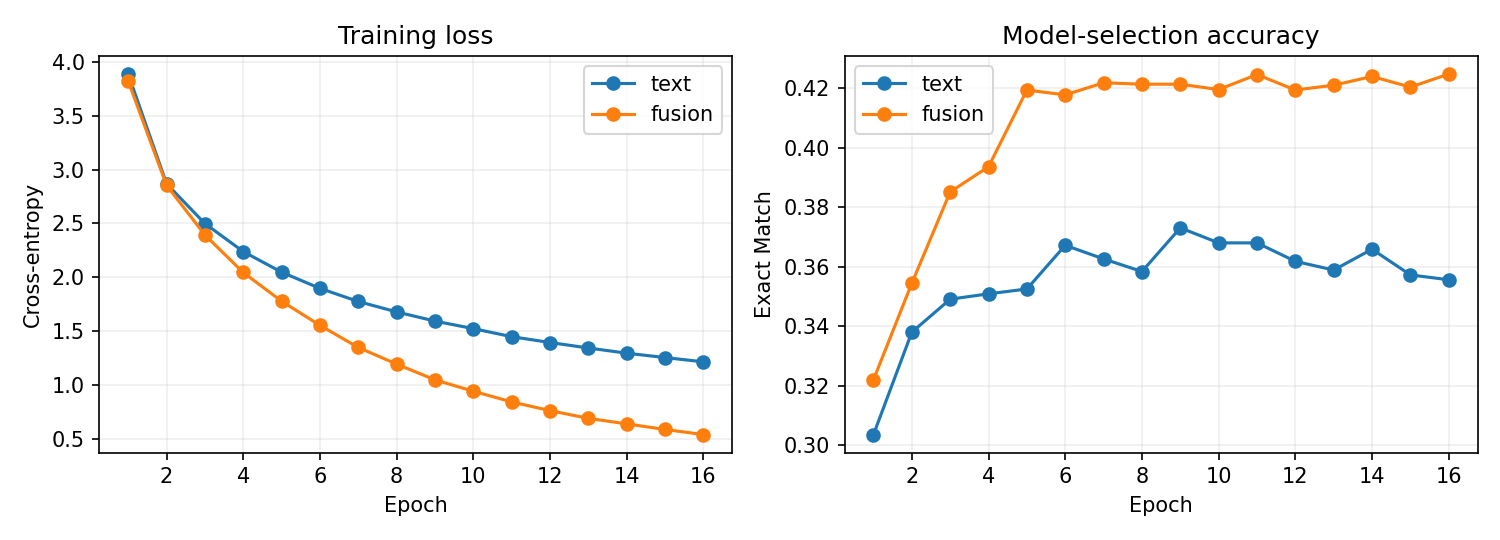

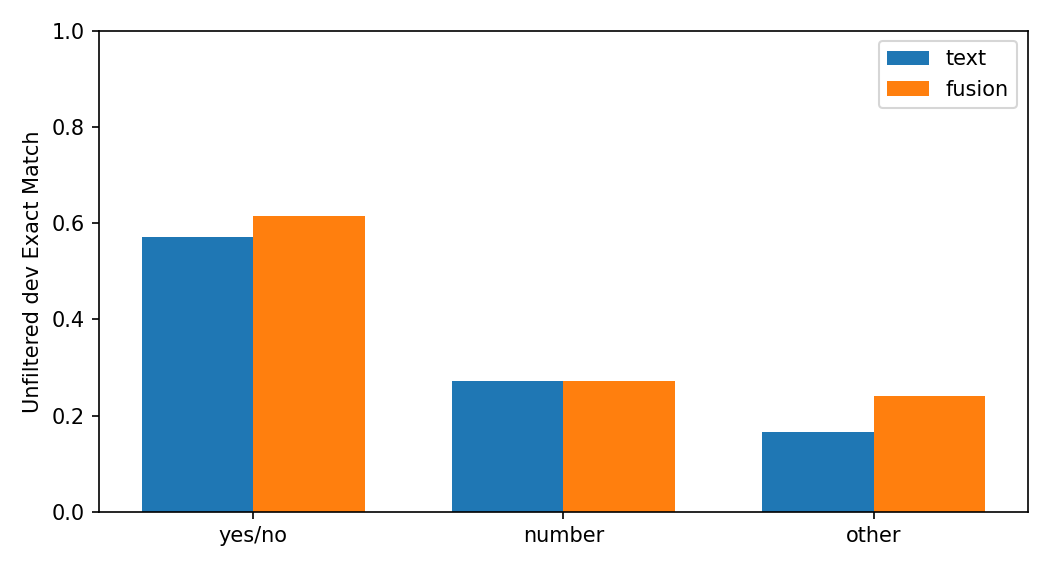

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for mode, history in (("text", text_history), ("fusion", fusion_history)):
    axes[0].plot([r["epoch"] for r in history], [r["train_loss"] for r in history],
                 marker="o", label=mode)
    axes[1].plot([r["epoch"] for r in history], [r["selection_accuracy"] for r in history],
                 marker="o", label=mode)
for axis in axes:
    axis.grid(alpha=0.2)
    axis.legend()
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy", title="Training loss")
axes[1].set(xlabel="Epoch", ylabel="Exact Match", title="Model-selection accuracy")
fig.tight_layout()
fig.savefig(RESULTS / "top1000_training_curves.png", dpi=150)
plt.close(fig)

fig, axis = plt.subplots(figsize=(7, 3.8))
types = list(by_type)
positions = list(range(len(types)))
axis.bar([x - 0.18 for x in positions],
         [by_type[t]["text"]["exact_match"] for t in types], 0.36, label="text")
axis.bar([x + 0.18 for x in positions],
         [by_type[t]["fusion"]["exact_match"] for t in types], 0.36, label="fusion")
axis.set_xticks(positions, types)
axis.set_ylim(0, 1)
axis.set_ylabel("Unfiltered dev Exact Match")
axis.legend()
fig.tight_layout()
fig.savefig(RESULTS / "top1000_by_type.png", dpi=150)
plt.close(fig)

summary = {
    "task": "VQA v2 Top-1000 answer classification, development set only",
    "seed": SEED, "epochs": EPOCHS, "selected_model": selected,
    "train_images": len(train_ids), "train_questions": len(train_rows),
    "dev_images": len(dev_ids), "dev_filtered_questions": len(dev_rows),
    "dev_all_questions": len(all_dev), "dev_vocab_coverage": coverage,
    "train_observed_answers": len(seen_train_labels),
    "dev_unseen_class_questions": unseen_dev_questions,
    "selection_images": len(selection_ids), "calibration_images": len(calibration_ids),
    "best_epoch": {"text": text_epoch, "fusion": fusion_epoch},
    "scores": evaluation, "by_answer_type": by_type,
    "temperatures": temperatures, "majority_answer": majority_answer,
    "head_trainable_params": sum(p.numel() for p in heads[selected].parameters()),
    "device": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU",
    "python": platform.python_version(), "torch": torch.__version__,
    "metric_note": "VQA-style 10-annotator agreement with short-answer normalization; official Test-Dev score requires EvalAI.",
}
(RESULTS / "top1000_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
torch.save({"state_dict": heads[selected].state_dict(), "vocabulary": vocabulary,
            "selected_model": selected, "temperature": temperatures[selected]},
           RESULTS / "top1000_head.pt")

probabilities = {mode: (logits / temperatures[mode]).softmax(1)
                 for mode, logits in all_logits.items()}
prediction_rows = []
for index, row in enumerate(all_dev):
    record = {key: row[key] for key in ("question_id", "image_id", "image",
                                         "question", "answer", "answer_type", "label_id")}
    record["models"] = {}
    for mode in ("text", "fusion"):
        probability, predicted_id = probabilities[mode][index].max(0)
        record["models"][mode] = {
            "answer": vocabulary[int(predicted_id)],
            "confidence": round(float(probability), 4),
            "exact_match": int(predicted_id) == row["label_id"],
            "vqa_style": round(vqa_style_score(vocabulary[int(predicted_id)],
                                               row["human_answers"]), 4),
        }
    prediction_rows.append(record)
(RESULTS / "top1000_predictions.json").write_text(
    json.dumps(prediction_rows, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Saved Top-1000 summary, {len(all_dev):,} development predictions, "
      "plots and local head checkpoint")
print("Selected model:", selected)


## 运行日志（RTX 4060，20,989 条 QA）

```text
Device: NVIDIA GeForce RTX 4060 Laptop GPU
Train: 20989 QA / 2000 images
Dev: 8083 in-vocab QA / 8969 total QA / 800 images; coverage=90.1%
Model selection: 6128 QA; calibration: 1955 QA
Training labels observed: 900/1000; in-vocabulary dev QA with unseen training label: 60
Unfiltered dev answer types: {'other': 4392, 'number': 1257, 'yes/no': 3320}
D:\vqa\venv\lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
Feature cache: top1000_features_f1c8a2ed61eb.pt
text   epoch=1 loss=3.8885 selection_acc=0.304
text   epoch=2 loss=2.8696 selection_acc=0.338
text   epoch=3 loss=2.4991 selection_acc=0.349
text   epoch=4 loss=2.2386 selection_acc=0.351
text   epoch=5 loss=2.0473 selection_acc=0.352
text   epoch=6 loss=1.8966 selection_acc=0.367
text   epoch=7 loss=1.7747 selection_acc=0.363
text   epoch=8 loss=1.6780 selection_acc=0.358
text   epoch=9 loss=1.5926 selection_acc=0.373
text   epoch=10 loss=1.5225 selection_acc=0.368
text   epoch=11 loss=1.4478 selection_acc=0.368
text   epoch=12 loss=1.3937 selection_acc=0.362
text   epoch=13 loss=1.3426 selection_acc=0.359
text   epoch=14 loss=1.2943 selection_acc=0.366
text   epoch=15 loss=1.2537 selection_acc=0.357
text   epoch=16 loss=1.2140 selection_acc=0.356
fusion epoch=1 loss=3.8236 selection_acc=0.322
fusion epoch=2 loss=2.8548 selection_acc=0.354
fusion epoch=3 loss=2.3933 selection_acc=0.385
fusion epoch=4 loss=2.0442 selection_acc=0.394
fusion epoch=5 loss=1.7776 selection_acc=0.419
fusion epoch=6 loss=1.5532 selection_acc=0.418
fusion epoch=7 loss=1.3476 selection_acc=0.422
fusion epoch=8 loss=1.1930 selection_acc=0.421
fusion epoch=9 loss=1.0464 selection_acc=0.421
fusion epoch=10 loss=0.9408 selection_acc=0.420
fusion epoch=11 loss=0.8415 selection_acc=0.425
fusion epoch=12 loss=0.7606 selection_acc=0.419
fusion epoch=13 loss=0.6889 selection_acc=0.421
fusion epoch=14 loss=0.6375 selection_acc=0.424
fusion epoch=15 loss=0.5855 selection_acc=0.420
fusion epoch=16 loss=0.5382 selection_acc=0.425
Selected fusion using selection accuracy; text=0.373, fusion=0.425
text filtered_dev {'exact_match': 0.36756154892985277, 'vqa_style': 0.4480267227514563, 'questions': 8083} unfiltered_dev {'exact_match': 0.3312520905340618, 'vqa_style': 0.40888616345189277, 'questions': 8969} temperature 1.217
fusion filtered_dev {'exact_match': 0.42558456018804897, 'vqa_style': 0.5109736483978764, 'questions': 8083} unfiltered_dev {'exact_match': 0.38354331586575985, 'vqa_style': 0.46572639090200035, 'questions': 8969} temperature 1.464
Selected model by answer type: {'yes/no': {'text': {'exact_match': 0.5710843373493976, 'vqa_style': 0.6986445783132521, 'questions': 3320}, 'fusion': {'exact_match': 0.6144578313253012, 'vqa_style': 0.7382228915662643, 'questions': 3320}}, 'number': {'text': {'exact_match': 0.27128082736674625, 'vqa_style': 0.33214001591089903, 'questions': 1257}, 'fusion': {'exact_match': 0.27128082736674625, 'vqa_style': 0.34232299124900606, 'questions': 1257}}, 'other': {'text': {'exact_match': 0.16712204007285975, 'vqa_style': 0.21181693989070957, 'questions': 4392}, 'fusion': {'exact_match': 0.24112021857923496, 'vqa_style': 0.29505919854280327, 'questions': 4392}}}
Saved Top-1000 summary, 5,547 development predictions, plots and local head checkpoint
Selected model: fusion
```
